In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

wine = load_wine()
X, y = wine.data, wine.target
print('Размер данных:', X.shape)
print('Объектов в каждом из трёх сортов:', np.bincount(y))

X_scaled = StandardScaler().fit_transform(X)

Размер данных: (178, 13)
Объектов в каждом из трёх сортов: [59 71 48]


In [2]:
def evaluate(X, labels, y_true):
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    sil = silhouette_score(X[mask], labels[mask]) if n_clusters >= 2 else np.nan
    ari = adjusted_rand_score(y_true, labels)
    return n_clusters, int((~mask).sum()), sil, ari

db_labels = DBSCAN(eps=1.5, min_samples=5).fit_predict(X_scaled)
db_clusters, db_noise, db_sil, db_ari = evaluate(X_scaled, db_labels, y)

print('Найдено кластеров:', db_clusters)
print('Точек помечено как шум:', db_noise, 'из', len(y))
print('silhouette_score:', db_sil)
print('adjusted_rand_score:', round(db_ari, 4))

Найдено кластеров: 0
Точек помечено как шум: 178 из 178
silhouette_score: nan
adjusted_rand_score: 0.0


In [3]:
km_labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_scaled)
km_clusters, km_noise, km_sil, km_ari = evaluate(X_scaled, km_labels, y)

print('silhouette_score:', round(km_sil, 4))
print('adjusted_rand_score:', round(km_ari, 4))

silhouette_score: 0.2849
adjusted_rand_score: 0.8975


### Сравнение

In [4]:
comparison = pd.DataFrame({
    'DBSCAN (eps=1.5, min_samples=5)': [db_clusters, db_noise, db_sil, db_ari],
    'KMeans (k=3)': [km_clusters, km_noise, km_sil, km_ari],
}, index=['Число кластеров', 'Точек-шума', 'silhouette', 'ARI']).T
print(comparison.round(4).to_string())

                                 Число кластеров  Точек-шума  silhouette     ARI
DBSCAN (eps=1.5, min_samples=5)              0.0       178.0         NaN  0.0000
KMeans (k=3)                                 3.0         0.0      0.2849  0.8975


In [5]:
rows = []
for eps in [1.5, 1.8, 2.0, 2.2, 2.4, 2.6, 3.0, 4.0]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    n_cl, n_noise, sil, ari = evaluate(X_scaled, labels, y)
    rows.append({'eps': eps, 'кластеров': n_cl, 'шум': n_noise, 'silhouette': sil, 'ARI': ari})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 eps  кластеров  шум  silhouette    ARI
 1.5          0  178         NaN  0.000
 1.8          7  118       0.246  0.084
 2.0          5   85       0.240  0.220
 2.2          2   55       0.348  0.329
 2.4          2   36       0.327  0.421
 2.6          1   20         NaN -0.000
 3.0          1   11         NaN -0.006
 4.0          1    3         NaN -0.005


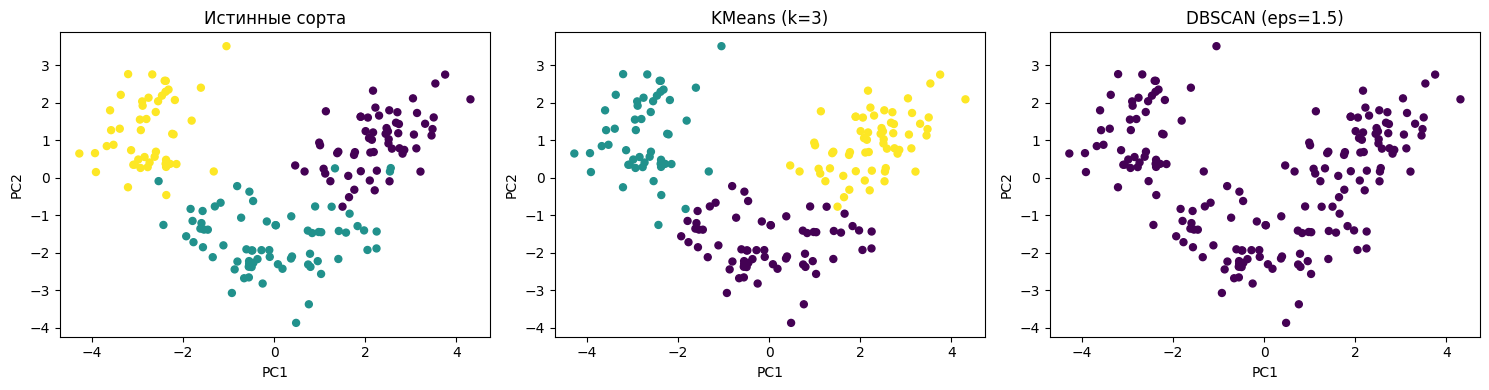

In [6]:
X_2d = PCA(n_components=2).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
panels = [('Истинные сорта', y), ('KMeans (k=3)', km_labels), ('DBSCAN (eps=1.5)', db_labels)]
for ax, (title, labels) in zip(axes, panels):
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='viridis', s=25)
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

### Проверка: что будет без масштабирования

In [7]:
db_raw = DBSCAN(eps=1.5, min_samples=5).fit_predict(X)
km_raw = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
print('DBSCAN без масштабирования: шум =', int((db_raw == -1).sum()), 'из', len(y))
print('KMeans без масштабирования: ARI =', round(adjusted_rand_score(y, km_raw), 4))

DBSCAN без масштабирования: шум = 178 из 178
KMeans без масштабирования: ARI = 0.3711
